# Fetal Health Classification: Decision Trees and Ensemble Learning

**Learning objective:** Build and compare supervised classification models that predict the
three numeric `fetal_health` categories from cardiotocography (CTG) measurements.

The workflow is reconstructed from a midterm report, not copied from an original notebook:
the PDF includes screenshots of evaluation code and results but omits much of its data-loading,
preprocessing, tuning, and model-construction code. This version fills those gaps explicitly.

**Models:** Decision Tree, Random Forest, Bagging, a *true* Stacking Classifier, and an
additional Voting Classifier that matches the estimator named in the original PDF's
“Stacked Models” confusion matrix. **Voting and stacking are not the same algorithm.**

**Important:** This is an educational exercise, *not* a clinically validated diagnostic tool.

In [11]:
"""Educational comparison of multiclass fetal-health classification methods.

Run as a script from a checked-out repository:
    python 07_Machine_Learning/Supervised_Learning/Fetal_Health_Classification/fetal_health_model_comparison.py

Or run the accompanying .ipynb file one cell at a time in Jupyter/Colab.

Source: study report screenshots; full original notebook code was not available.
"""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    StackingClassifier,
    VotingClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
    cross_val_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import label_binarize
from sklearn.tree import DecisionTreeClassifier

# A fixed seed gives repeatable random splits and model sampling.
# Reproducibility matters when comparing algorithms in research.
RANDOM_STATE = 42
TEST_SIZE = 0.30
CV_FOLDS = 3
N_SEARCH_ITERATIONS = 4  # Increase for a more extensive hyperparameter search.
DROP_EXACT_DUPLICATES = True
TARGET_COLUMN = "fetal_health"

# These are categorical codes, even though the CSV stores them as floats.
# Using numeric codes directly avoids adding an unnecessary label encoder.
CLASS_VALUES = [1, 2, 3]
CLASS_LABELS = ["Class 1", "Class 2", "Class 3"]
OUTPUT_DIR = Path("outputs") / "fetal_health_classification"


## 1 — Load, inspect, and understand the data

The CSV contains **2,126 rows, 21 predictor columns, and one target**.
The three target classes are unevenly represented, so a random split without
stratification can accidentally underrepresent minority classes. We inspect missing
values and duplicate rows before training, and avoid interpreting these class codes
as continuous measurements.

The dataset supplied with this repository does not include descriptions of the target
categories. This notebook therefore reports them neutrally as Class 1/2/3.

In [12]:
def locate_dataset():
    """Find the CSV in the repository, or beside the notebook in Google Colab.

    Path.cwd() is typically the project root for a local Jupyter session and
    /content for Colab. Search ancestor folders so the code remains reusable
    when the working directory changes.
    """
    working_dir = Path.cwd()
    for folder in [working_dir, *working_dir.parents]:
        for candidate in (
            folder / "datasets" / "fetal_health.csv",
            folder / "fetal_health.csv",  # e.g., a file uploaded to Colab
        ):
            if candidate.is_file():
                return candidate
    raise FileNotFoundError(
        "Cannot find fetal_health.csv. Put it in your repository's datasets/ "
        "folder, or upload it to the current notebook directory in Colab."
    )


def load_and_inspect_data():
    """Read the source data and report possible data-quality concerns."""
    source = locate_dataset()
    df = pd.read_csv(source)

    # Every non-target column is an input feature; the target is what we predict.
    # The target must NEVER appear in X, or the model could simply read the answer.
    if TARGET_COLUMN not in df.columns:
        raise ValueError(f"Target column {TARGET_COLUMN!r} was not found.")

    print(f"Dataset path: {source}")
    print(f"Initial dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
    print("Missing values:", int(df.isna().sum().sum()))
    print("Exact duplicate rows:", int(df.duplicated().sum()))
    print("\nOriginal class distribution:")
    print(df[TARGET_COLUMN].value_counts().sort_index())
    print("\nSample measurements:")
    print(df.head(3).to_string(index=False))

    # Fail early on an unexpected schema rather than training on wrong targets.
    actual_classes = set(df[TARGET_COLUMN].dropna().astype(int).unique())
    if actual_classes != set(CLASS_VALUES):
        raise ValueError(f"Unexpected target classes: {actual_classes}")

    return df


## 2 — Prepare features without leaking test information

**Data leakage** happens when information from the test set affects training.
Therefore, we split the data **before fitting any preprocessing operation**.
Median imputation is fitted *inside* each model's `Pipeline`; cross-validation
then learns imputation statistics from each training fold only.

The provided CSV has no nulls, so the imputer is primarily a best-practice example.
**No feature scaling is necessary for decision trees and tree-based ensembles**;
the stacker's logistic-regression meta-model uses predicted probabilities, which
are already between zero and one.

There are 13 exact duplicates. Here, we remove them **before** splitting to avoid
identical records entering train and test. In real clinical data, repeated records
may be legitimate distinct observations: check their provenance before deleting them.

In [13]:
def prepare_train_test(df):
    """Perform defensible cleaning and make one untouched stratified test set."""
    data = df.copy()

    if DROP_EXACT_DUPLICATES:
        before = len(data)
        data = data.drop_duplicates().reset_index(drop=True)
        print(f"Removed {before - len(data)} exact duplicate rows.")

    # A target is missing for some records in other datasets. They cannot be used
    # for supervised training, because the correct label is unknown.
    data = data.dropna(subset=[TARGET_COLUMN])

    # Convert the coded labels 1.0, 2.0, 3.0 to the equivalent integer categories.
    # They remain categorical targets; no numerical ordering is assumed by trees.
    y = data[TARGET_COLUMN].astype(int)
    X = data.drop(columns=[TARGET_COLUMN]).copy()

    # Ensure all inputs are numeric. Unexpected strings become missing values,
    # which the training-fold-only imputer will handle after splitting.
    for column in X.columns:
        X[column] = pd.to_numeric(X[column], errors="coerce")

    # Stratification approximately maintains the original percentages of all
    # three classes in both partitions, especially helpful with class imbalance.
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=y,
    )

    print(f"Training examples: {len(X_train)} | Test examples: {len(X_test)}")
    print("Training label proportions:", y_train.value_counts(normalize=True).sort_index().round(3).to_dict())
    print("Test label proportions:", y_test.value_counts(normalize=True).sort_index().round(3).to_dict())
    return X_train, X_test, y_train, y_test


## 3 — Model selection with cross-validation

The first three classifiers are trained and tuned using **stratified 3-fold
cross-validation** on the training partition only:

- **Decision Tree:** recursively splits features to reduce class impurity.
  Depth and leaf-size controls prevent an overly specific tree from memorizing rows.
- **Random Forest:** averages many independently randomized trees (bootstrap samples
  and feature subsampling) to reduce prediction variance.
- **Bagging:** trains many versions of a base estimator on bootstrap samples.
  Unlike a random forest, ordinary bagged trees do not inherently subsample
  features at every split.

We optimize **macro F1**, giving each class equal weight rather than rewarding
only the majority class. `RandomizedSearchCV` samples candidate settings rather
than trying every combination. Four iterations keep the study runnable; increase
this value when computational resources permit.

In [14]:
def make_pipeline(estimator):
    """Tie data preprocessing to each classifier for leakage-safe CV."""
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", estimator),
    ])


def define_model_searches():
    """Define explicitly reproducible model families and parameter spaces."""
    searches = {
        "Decision Tree": (
            make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
            {
                # A smaller max_depth limits how intricate a learned tree can be.
                "model__max_depth": [4, 6, 10, 15, None],
                # More samples per leaf can reduce overfitting to unusual points.
                "model__min_samples_leaf": [1, 2, 4, 8],
                "model__criterion": ["gini", "entropy"],
            },
        ),
        "Random Forest": (
            make_pipeline(RandomForestClassifier(
                random_state=RANDOM_STATE,
                n_jobs=1,  # Outer CV handles evaluation; avoid nested oversubscription.
            )),
            {
                "model__n_estimators": [50, 100, 150],
                "model__max_depth": [6, 12, None],
                "model__min_samples_leaf": [1, 2, 4],
                "model__max_features": ["sqrt", 0.8],
            },
        ),
        "Bagging": (
            make_pipeline(BaggingClassifier(
                estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                random_state=RANDOM_STATE,
                n_jobs=1,
            )),
            {
                "model__n_estimators": [40, 80, 150],
                "model__max_samples": [0.75, 1.0],
                "model__estimator__max_depth": [8, None],
                "model__estimator__min_samples_leaf": [1, 2, 4],
            },
        ),
    }
    return searches


def tune_base_models(X_train, y_train, cv):
    """Fit tuning searches without ever looking at the test set."""
    fitted = {}
    train_cv_scores = {}

    for name, (model, param_space) in define_model_searches().items():
        search = RandomizedSearchCV(
            estimator=model,
            param_distributions=param_space,
            n_iter=N_SEARCH_ITERATIONS,
            scoring="f1_macro",  # Equal importance for all 3 classes.
            cv=cv,
            n_jobs=1,
            refit=True,  # Retrain the best setting on the full training partition.
            random_state=RANDOM_STATE,
            error_score="raise",
        )
        search.fit(X_train, y_train)
        fitted[name] = search.best_estimator_
        train_cv_scores[name] = search.best_score_
        print(f"\n{name} | best training-CV macro F1: {search.best_score_:.4f}")
        print("Chosen hyperparameters:", search.best_params_)

    return fitted, train_cv_scores


## 4 — Ensemble learning: voting and stacking are different

**Voting** combines the probability predictions of several separately trained
classifiers (soft voting). This is the model type explicitly visible in the PDF's
confusion-matrix caption, even though its section is titled “Stacked Models”.

**Stacking** trains a *second-level model* (the meta-learner) on predictions from
base models. `StackingClassifier` creates out-of-fold training predictions for
that meta-learner so it cannot simply learn from predictions evaluated on the
same rows that trained the underlying trees. We tune the logistic regression
meta-learner's `C` value on the training folds.

Both are included for teaching clarity. Their scores can differ from the PDF
because the original preprocessing, split, and hyperparameter settings were not
available in full.

In [15]:
def build_and_tune_ensembles(base_models, X_train, y_train, cv):
    """Compare probability voting with genuine learned stacking."""
    # clone() keeps hyperparameters but clears fitted state. Each ensemble
    # subsequently learns from X_train; nothing from X_test is ever used.
    voting = VotingClassifier(
        estimators=[
            ("tree", clone(base_models["Decision Tree"])),
            ("forest", clone(base_models["Random Forest"])),
            ("bag", clone(base_models["Bagging"])),
        ],
        voting="soft",  # Average probabilities instead of majority class labels.
        n_jobs=1,
    )

    # For a comparable train-only estimate, evaluate the voting ensemble using
    # the same folds as the other model families.
    voting_scores = cross_val_score(
        voting, X_train, y_train, scoring="f1_macro", cv=cv, n_jobs=1
    )
    voting.fit(X_train, y_train)

    # Stacking has different mechanics: a meta-classifier learns which base
    # model predictions to trust, using internally cross-validated predictions.
    stacking = StackingClassifier(
        estimators=[
            ("tree", clone(base_models["Decision Tree"])),
            ("forest", clone(base_models["Random Forest"])),
        ],
        final_estimator=LogisticRegression(
            max_iter=1500,
            random_state=RANDOM_STATE,
        ),
        stack_method="predict_proba",
        cv=3,  # Inner folds create out-of-fold meta-learner features.
        passthrough=False,  # Meta-learner sees probabilities, not raw predictors.
        n_jobs=1,
    )

    # Tune the meta-learner using OUTER cross-validation restricted to X_train.
    # That is computationally more expensive but avoids choosing C on test data.
    stack_search = GridSearchCV(
        stacking,
        param_grid={"final_estimator__C": [0.1, 1.0]},
        cv=cv,
        scoring="f1_macro",
        n_jobs=1,
        refit=True,
        error_score="raise",
    )
    stack_search.fit(X_train, y_train)

    print(f"\nVoting | training-CV macro F1: {np.mean(voting_scores):.4f}")
    print(f"Stacking | best training-CV macro F1: {stack_search.best_score_:.4f}")
    print("Chosen stacking hyperparameters:", stack_search.best_params_)

    return (
        {"Voting": voting, "Stacking": stack_search.best_estimator_},
        {"Voting": float(np.mean(voting_scores)), "Stacking": stack_search.best_score_},
    )


## 5 — Evaluate generalization on the untouched test set

**Accuracy** is the fraction of all correctly classified examples. It is easy
to interpret but can be misleading when Class 1 is much more frequent.

**Precision** asks: of the samples predicted as a class, how many actually belong
to that class? **Recall** asks: of the true samples in a class, how many did the
model correctly detect? Both macro and weighted averaging are reported.
Macro averaging treats all classes equally; weighted averaging gives each class
weight according to its frequency. **Macro F1** is included as the mean of the
class-specific F1 scores.

**Multiclass ROC AUC:** compute one-vs-rest (OvR) AUC for each class using predicted
probabilities and summarize with a weighted average. Plot one ROC curve per
class rather than treating class 1, 2, and 3 as a single binary label. This
also fixes a mismatch in the PDF between weighted multiclass AUC and its
flattened ROC curve.

**Confusion matrix:** rows are true classes, columns are predictions. The diagonal
shows correct cases; off-diagonal cells show the mistakes worth investigating.

In [16]:
def save_confusion_matrix(y_true, y_pred, model_name):
    """Visualize which *actual* categories were mistaken for each prediction."""
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ConfusionMatrixDisplay.from_predictions(
        y_true,
        y_pred,
        labels=CLASS_VALUES,
        display_labels=CLASS_LABELS,
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(f"{model_name}: Confusion Matrix")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{model_name.lower().replace(' ', '_')}_confusion_matrix.png", dpi=150)
    # Headless Python scripts save figures; notebooks can also display them.
    if plt.get_backend().lower() != "agg":
        plt.show()
    plt.close(fig)


def save_multiclass_roc(y_true, probabilities, model_name):
    """Draw a correct one-vs-rest ROC curve separately for each of 3 classes."""
    # Each column denotes one binary question: is this observation in class k?
    y_binary = label_binarize(y_true, classes=CLASS_VALUES)
    fig, ax = plt.subplots(figsize=(7, 5.5))

    for index, label in enumerate(CLASS_LABELS):
        # Probabilities must be aligned to CLASS_VALUES; see evaluate_model().
        false_positive_rate, true_positive_rate, _ = roc_curve(
            y_binary[:, index], probabilities[:, index]
        )
        class_auc = roc_auc_score(y_binary[:, index], probabilities[:, index])
        ax.plot(false_positive_rate, true_positive_rate, label=f"{label}: AUC {class_auc:.3f}")

    ax.plot([0, 1], [0, 1], "--", color="gray", label="Chance baseline")
    ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate",
           title=f"{model_name}: One-vs-Rest ROC Curves")
    ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{model_name.lower().replace(' ', '_')}_roc.png", dpi=150)
    # Headless Python scripts save figures; notebooks can also display them.
    if plt.get_backend().lower() != "agg":
        plt.show()
    plt.close(fig)


def evaluate_model(name, model, X_test, y_test, training_cv_macro_f1):
    """Measure performance exactly once on the held-out test split."""
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)

    # Estimators normally provide sorted model.classes_, but explicitly verify
    # that their probability columns match our documented class order.
    if list(model.classes_) != CLASS_VALUES:
        raise ValueError(f"{name}: probability columns have unexpected class order")

    # Weighted multiclass ROC AUC matches the definition (OvR + weighted)
    # used in the report. Plotted curves above are separate per-class OvR ROC.
    roc_auc = roc_auc_score(
        y_test, probabilities,
        labels=CLASS_VALUES,
        multi_class="ovr",
        average="weighted",
    )

    metrics = {
        "model": name,
        "train_cv_macro_f1": training_cv_macro_f1,
        "accuracy": accuracy_score(y_test, predictions),
        "precision_macro": precision_score(y_test, predictions, average="macro", zero_division=0),
        "recall_macro": recall_score(y_test, predictions, average="macro", zero_division=0),
        "f1_macro": f1_score(y_test, predictions, average="macro", zero_division=0),
        "precision_weighted": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "recall_weighted": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "roc_auc_ovr_weighted": roc_auc,
    }

    print(f"\n{name} | held-out accuracy: {metrics['accuracy']:.3f}")
    print(classification_report(
        y_test, predictions, labels=CLASS_VALUES,
        target_names=CLASS_LABELS, zero_division=0
    ))
    save_confusion_matrix(y_test, predictions, name)
    save_multiclass_roc(y_test, probabilities, name)
    return metrics


## 6 — Compare models and reflect on the results

We save each model's results to a CSV to make the experiment easy to reproduce
and compare later. **Training CV macro F1** is the metric used for choosing
hyperparameters. Test metrics are reported separately so test data never
influences model tuning.

When interpreting the table, check **per-class recall and confusion matrices**,
not only overall accuracy. With an imbalanced health dataset, a model can be
very accurate overall while failing to detect one of the less common classes.

The original PDF reported roughly 92–95% accuracy, with Bagging and Random
Forest performing well. This reconstructed, leakage-conscious experiment uses
a stratified split and verified evaluation procedure, so its numerical results
**should not be expected to match the PDF exactly**.

In [17]:
def main():
    """Run the complete experiment and save a model-comparison CSV and plots."""
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    df = load_and_inspect_data()
    X_train, X_test, y_train, y_test = prepare_train_test(df)

    # All model selection uses the training partition and stratified folds.
    # StratifiedKFold reduces noisy performance swings for minority classes.
    cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

    base_models, base_cv_scores = tune_base_models(X_train, y_train, cv)
    ensemble_models, ensemble_cv_scores = build_and_tune_ensembles(
        base_models, X_train, y_train, cv
    )

    models = {**base_models, **ensemble_models}
    training_scores = {**base_cv_scores, **ensemble_cv_scores}
    rows = []
    for name, model in models.items():
        rows.append(evaluate_model(name, model, X_test, y_test, training_scores[name]))

    # Display a single comparison; do not retune models after seeing test scores.
    results = pd.DataFrame(rows).sort_values("f1_macro", ascending=False)
    results = results.reset_index(drop=True)
    print("\n=== HELD-OUT MODEL COMPARISON ===")
    print(results.round(4).to_string(index=False))
    results.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
    print(f"\nSaved plots and metrics to: {OUTPUT_DIR.resolve()}")
    print("Reminder: these scores are educational and not clinical validation.")
    return results




## Run the experiment

In **Google Colab**, first upload `fetal_health.csv` using the left **Files** panel, or clone the GitHub repository. Run all cells in order. Results and figures will be written under `outputs/fetal_health_classification/` in the current working directory.

Dataset path: /content/fetal_health.csv
Initial dimensions: 2126 rows, 22 columns
Missing values: 0
Exact duplicate rows: 13

Original class distribution:
fetal_health
1.0    1655
2.0     295
3.0     176
Name: count, dtype: int64

Sample measurements:
 baseline value  accelerations  fetal_movement  uterine_contractions  light_decelerations  severe_decelerations  prolongued_decelerations  abnormal_short_term_variability  mean_value_of_short_term_variability  percentage_of_time_with_abnormal_long_term_variability  mean_value_of_long_term_variability  histogram_width  histogram_min  histogram_max  histogram_number_of_peaks  histogram_number_of_zeroes  histogram_mode  histogram_mean  histogram_median  histogram_variance  histogram_tendency  fetal_health
          120.0          0.000             0.0                 0.000                0.000                   0.0                       0.0                             73.0                                   0.5                                

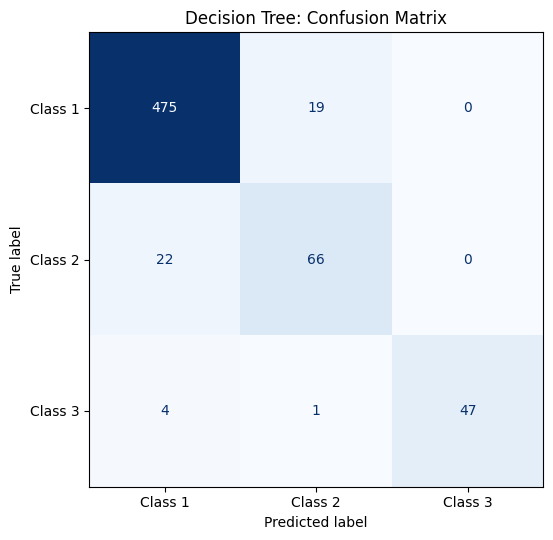

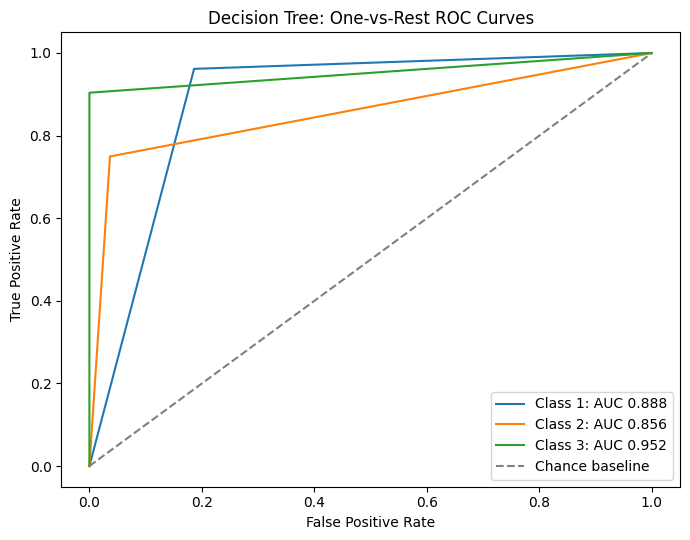


Random Forest | held-out accuracy: 0.940
              precision    recall  f1-score   support

     Class 1       0.95      0.98      0.96       494
     Class 2       0.87      0.70      0.78        88
     Class 3       0.96      0.94      0.95        52

    accuracy                           0.94       634
   macro avg       0.93      0.88      0.90       634
weighted avg       0.94      0.94      0.94       634



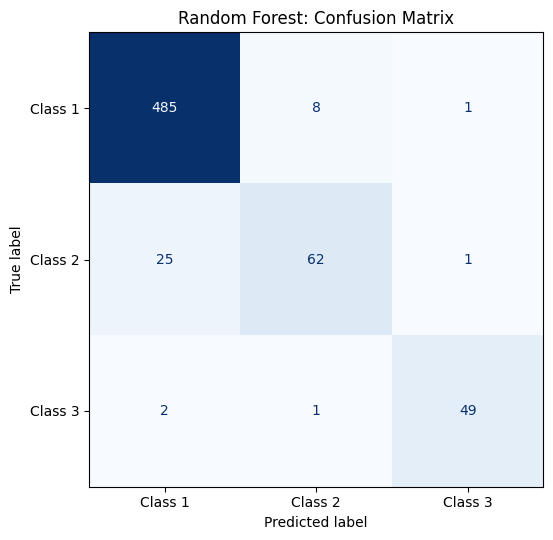

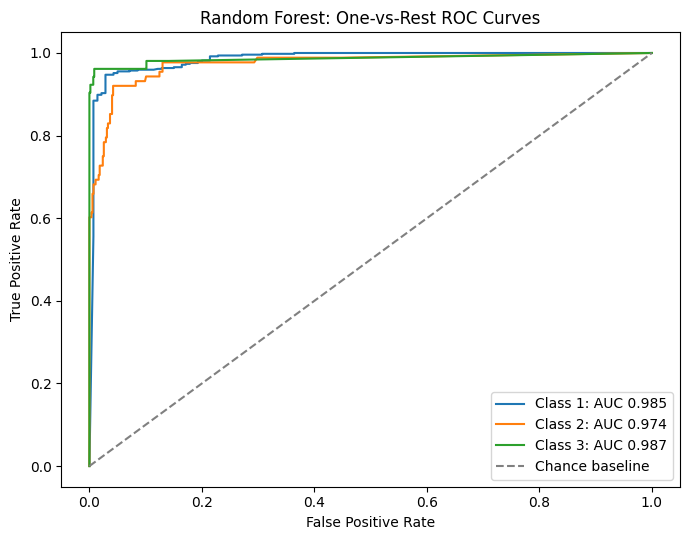


Bagging | held-out accuracy: 0.940
              precision    recall  f1-score   support

     Class 1       0.95      0.98      0.96       494
     Class 2       0.88      0.72      0.79        88
     Class 3       0.94      0.94      0.94        52

    accuracy                           0.94       634
   macro avg       0.92      0.88      0.90       634
weighted avg       0.94      0.94      0.94       634



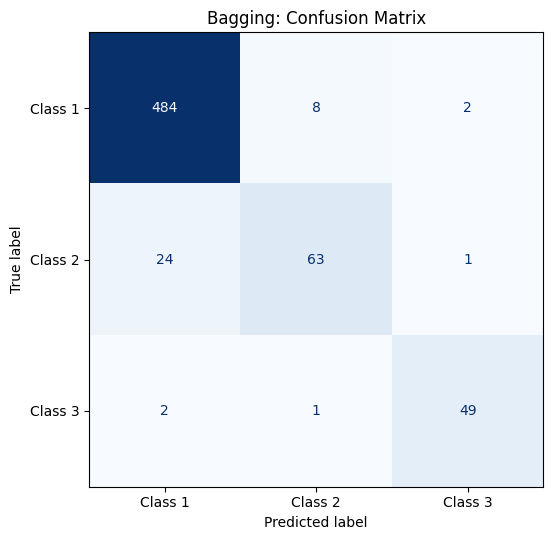

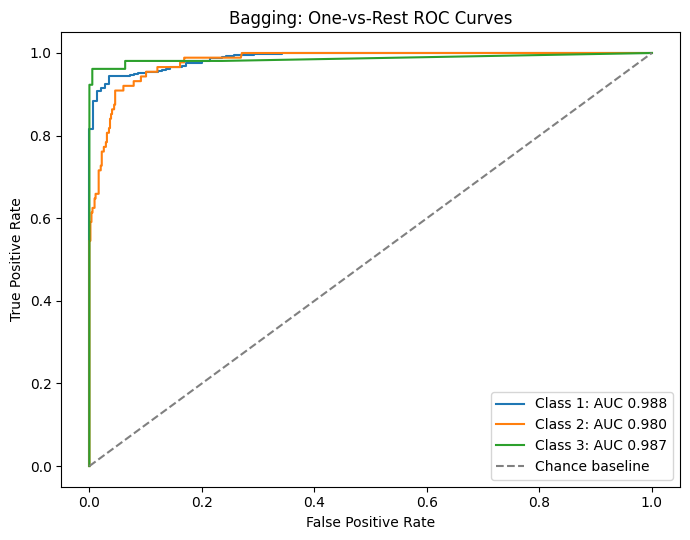


Voting | held-out accuracy: 0.942
              precision    recall  f1-score   support

     Class 1       0.95      0.98      0.96       494
     Class 2       0.85      0.76      0.80        88
     Class 3       1.00      0.90      0.95        52

    accuracy                           0.94       634
   macro avg       0.93      0.88      0.91       634
weighted avg       0.94      0.94      0.94       634



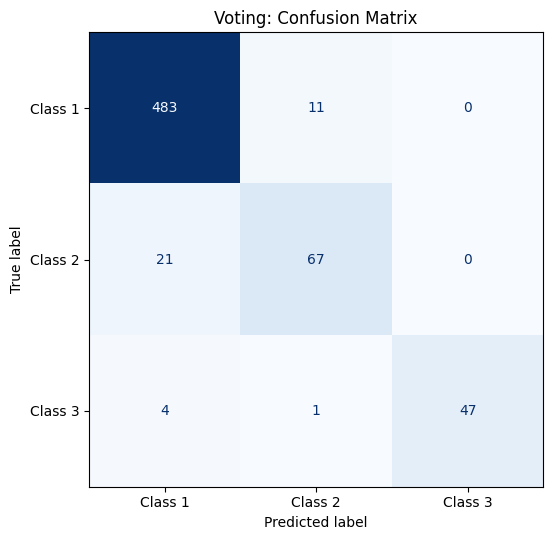

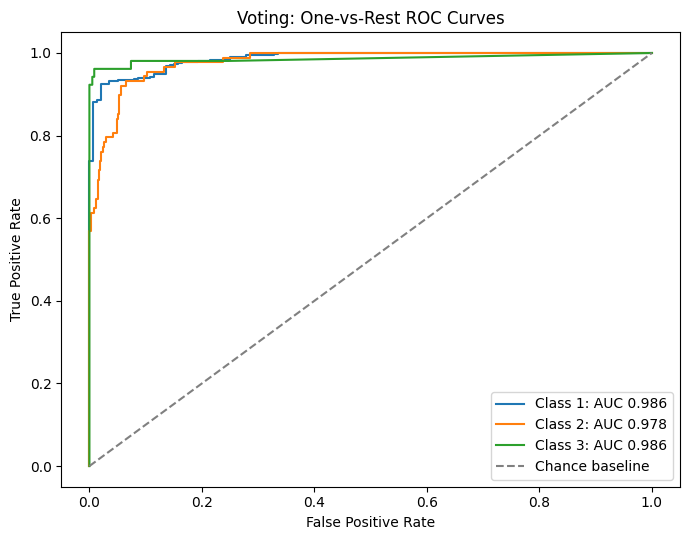


Stacking | held-out accuracy: 0.940
              precision    recall  f1-score   support

     Class 1       0.95      0.98      0.96       494
     Class 2       0.85      0.72      0.78        88
     Class 3       1.00      0.92      0.96        52

    accuracy                           0.94       634
   macro avg       0.93      0.87      0.90       634
weighted avg       0.94      0.94      0.94       634



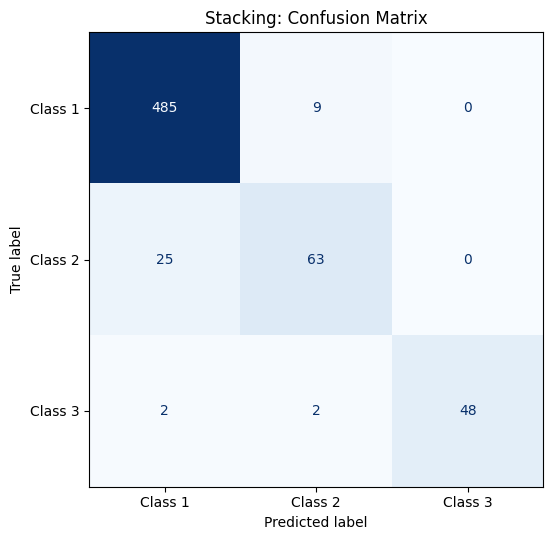

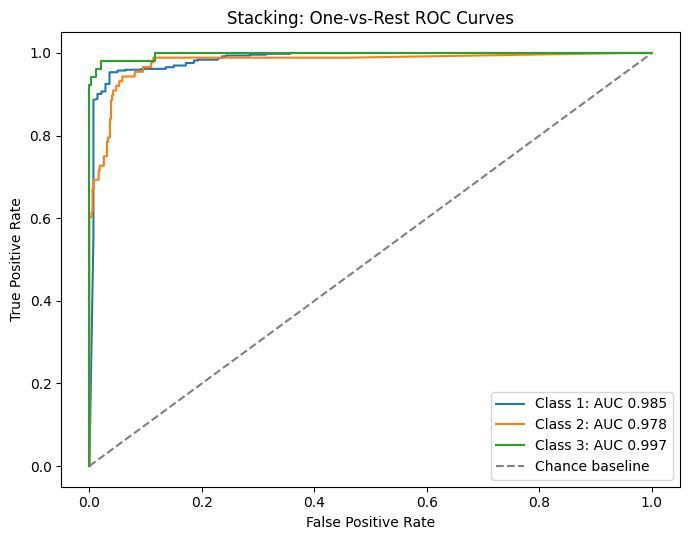


=== HELD-OUT MODEL COMPARISON ===
        model  train_cv_macro_f1  accuracy  precision_macro  recall_macro  f1_macro  precision_weighted  recall_weighted  roc_auc_ovr_weighted
       Voting             0.8553    0.9416           0.9330        0.8810    0.9053              0.9406           0.9416                0.9852
     Stacking             0.8683    0.9401           0.9329        0.8736    0.9007              0.9383           0.9401                0.9852
Random Forest             0.8766    0.9401           0.9271        0.8762    0.8985              0.9381           0.9401                0.9838
      Bagging             0.8696    0.9401           0.9221        0.8793    0.8980              0.9382           0.9401                0.9868
Decision Tree             0.8320    0.9274           0.9052        0.8718    0.8876              0.9273           0.9274                0.8886

Saved plots and metrics to: /content/outputs/fetal_health_classification
Reminder: these scores are educat

,model,train_cv_macro_f1,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,roc_auc_ovr_weighted
0,Voting,0.855322,0.941640,0.932963,0.880981,0.905321,0.940571,0.941640,0.985229
1,Stacking,0.868310,0.940063,0.932872,0.873589,0.900664,0.938278,0.940063,0.985230
2,Random Forest,0.876550,0.940063,0.927096,0.876212,0.898515,0.938099,0.940063,0.983803
3,Bagging,0.869647,0.940063,0.922109,0.879325,0.897984,0.938195,0.940063,0.986812
4,Decision Tree,0.831989,0.927445,0.905182,0.871795,0.887630,0.927284,0.927445,0.888650


In [18]:
results = main()
results